In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv("D:/Important Files/Machine Learning/Datasets/data.csv")
df = df.drop(columns=["id", "Unnamed: 32"])

X = df.drop(columns="diagnosis")
y = df["diagnosis"].map({"B": 0, "M": 1})

df["diagnosis"].value_counts()

diagnosis
B    357
M    212
Name: count, dtype: int64

Three-way split: **train** to fit the models, **validation** for early stopping, and **test** only for the final comparison. Early stopping must use a validation set. If it used the test set, the test score would no longer be an honest estimate.

In [3]:
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp)

X_train.shape, X_val.shape, X_test.shape

((341, 30), (114, 30), (114, 30))

Two small helpers keep the comparison consistent: one times the fit, one records test metrics.

In [4]:
results = []

def fit_timed(model, **fit_kwargs):
    start = time.perf_counter()
    model.fit(X_train, y_train, **fit_kwargs)
    return time.perf_counter() - start

def evaluate(name, model, fit_seconds):
    proba = model.predict_proba(X_test)[:, 1]
    results.append({
        "model": name,
        "test accuracy": accuracy_score(y_test, model.predict(X_test)),
        "test ROC-AUC": roc_auc_score(y_test, proba),
        "fit time (s)": fit_seconds,
    })

## 1. Single decision tree (baseline):

In [5]:
dt = DecisionTreeClassifier(random_state=42)
secs = fit_timed(dt)
evaluate("Decision tree", dt, secs)

results[-1]

{'model': 'Decision tree',
 'test accuracy': 0.9035087719298246,
 'test ROC-AUC': 0.888888888888889,
 'fit time (s)': 0.009184800001094118}

## 2. Gradient Boosting (scikit-learn):

In [6]:
gbm = GradientBoostingClassifier(random_state=42)
secs = fit_timed(gbm)
evaluate("Gradient Boosting (sklearn)", gbm, secs)

results[-1]

{'model': 'Gradient Boosting (sklearn)',
 'test accuracy': 0.9649122807017544,
 'test ROC-AUC': 0.9927248677248678,
 'fit time (s)': 0.21569650000310503}

## 3. XGBoost:

First with mostly default settings: 100 trees, no validation set, no early stopping.

In [7]:
xgb_default = XGBClassifier(eval_metric="logloss", random_state=42)
secs = fit_timed(xgb_default)
evaluate("XGBoost (defaults)", xgb_default, secs)

results[-1]

{'model': 'XGBoost (defaults)',
 'test accuracy': 0.9736842105263158,
 'test ROC-AUC': 0.9953703703703705,
 'fit time (s)': 0.09164939998299815}

### XGBoost with early stopping:

Instead of guessing the number of trees, set a generous upper limit (`n_estimators=1000`) with a small learning rate, and stop when the validation log-loss hasn't improved for 30 rounds. `subsample` and `colsample_bytree` below 1 add randomness that helps against overfitting, and `reg_lambda` is the L2 penalty on leaf values.

In [8]:
xgb_es = XGBClassifier(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    eval_metric="logloss",
    early_stopping_rounds=30,
    importance_type="gain",
    random_state=42,
)

secs = fit_timed(xgb_es, eval_set=[(X_val, y_val)], verbose=False)
evaluate("XGBoost (early stopping)", xgb_es, secs)

print("Best iteration:", xgb_es.best_iteration)
print("Best validation log-loss:", round(xgb_es.best_score, 4))

Best iteration: 138
Best validation log-loss: 0.1119


The validation curve shows why early stopping helps: the loss falls quickly, flattens, and training stops 30 rounds after the best point.

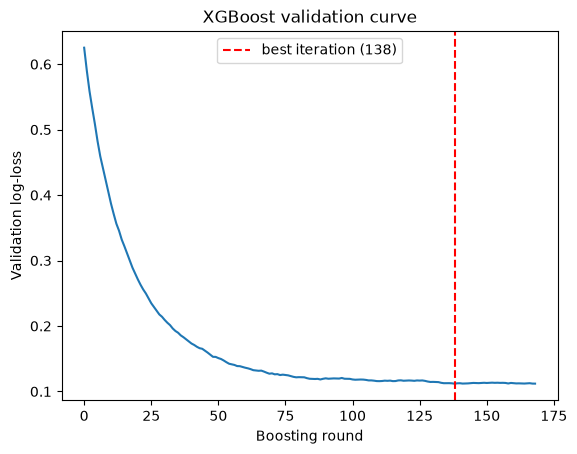

In [9]:
val_loss = xgb_es.evals_result()["validation_0"]["logloss"]

plt.plot(val_loss)
plt.axvline(xgb_es.best_iteration, color="red", linestyle="--", label=f"best iteration ({xgb_es.best_iteration})")
plt.xlabel("Boosting round")
plt.ylabel("Validation log-loss")
plt.title("XGBoost validation curve")
plt.legend()
plt.show()

## 4. Feature importances:

XGBoost's importance here is **gain**: the average loss reduction from splits that use the feature. scikit-learn's Gradient Boosting reports impurity-based importance. Both are normalized to sum to 1, so they are comparable side by side.

Treat both with some caution: when features are strongly correlated (as many of these measurements are), the credit is shared between them somewhat arbitrarily.

In [10]:
importances = pd.DataFrame({
    "XGBoost (gain)": xgb_es.feature_importances_,
    "Gradient Boosting (impurity)": gbm.feature_importances_,
}, index=X.columns)

top = importances.sort_values("XGBoost (gain)", ascending=False).head(10)
top.round(4)

,XGBoost (gain),Gradient Boosting (impurity)
perimeter_worst,0.2680,0.4561
concave points_mean,0.2009,0.1431
radius_worst,0.0861,0.1300
concave points_worst,0.0659,0.0675
area_worst,0.0478,0.0267
concavity_worst,0.0395,0.0225
area_mean,0.0360,0.0027
concavity_mean,0.0292,0.0019
compactness_worst,0.0246,0.0041
texture_mean,0.0232,0.0479


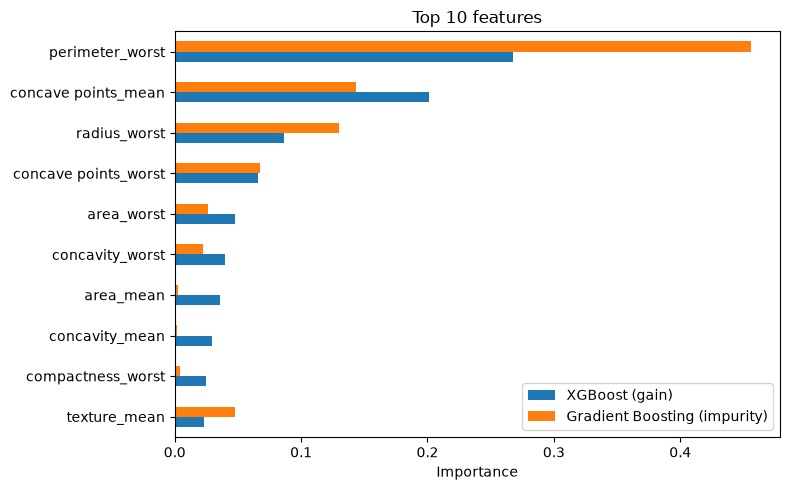

In [11]:
top.sort_values("XGBoost (gain)").plot(kind="barh", figsize=(8, 5))
plt.title("Top 10 features")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## 5. Comparison:

In [12]:
summary = pd.DataFrame(results).set_index("model").round(4)

n_test = len(y_test)
se = np.sqrt(0.95 * 0.05 / n_test)
print(f"One test row = {100 / n_test:.1f} accuracy points; "
      f"rough standard error at ~95% accuracy = {se * 100:.1f} points")

summary

One test row = 0.9 accuracy points; rough standard error at ~95% accuracy = 2.0 points


,test accuracy,test ROC-AUC,fit time (s)
model,,,
Decision tree,0.9035,0.8889,0.0092
Gradient Boosting (sklearn),0.9649,0.9927,0.2157
XGBoost (defaults),0.9737,0.9954,0.0916
XGBoost (early stopping),0.9825,0.9960,0.1054


**Takeaways**

- On a small dataset like this, differences of a few test rows are within noise. Look at ROC-AUC as well as accuracy, and don't over-read a one-row gap.
- A single tree is typically the weakest and least stable of the three, since boosting combines many shallow trees that each correct the previous ones' errors. Check the table to see whether that holds here.
- Fit times on 341 training rows are tiny and not representative. XGBoost's speed advantage over scikit-learn's Gradient Boosting shows up on much larger data.
- Early stopping picks the number of trees from a validation set, so there is one less hyperparameter to guess. Always keep the test set out of that decision.